# Modelo de demanda, versión 2: calendario y clima

Misma tabla, misma partición por fechas y mismos hiperparámetros que la versión 1 (`02_modelo.ipynb`),
más dos grupos de variables:

- **Calendario** (ciclo escolar SEP 2025-2026): `vacaciones_sep` (30 mar – 10 abr y 16 jul – 30 ago) y
  `es_festivo` (16 mar, 2 y 3 abr, 1 may).
- **Clima por hora** (histórico de Open-Meteo, un punto en el centro de la zona Ecobici): `lluvia_mm` y `temperatura`.

Motivo: el periodo de prueba (28 jul – 31 ago) cae completo en vacaciones de verano y en temporada de lluvias,
y la versión 1 no tenía forma de saberlo. Se comparan cuatro variantes de XGBoost para ver cuánto aporta cada grupo.

Nota: el clima es el **observado**, no un pronóstico. El resultado es una cota superior de lo que se lograría
prediciendo con una semana de anticipación con el pronóstico del clima.

In [1]:
import sys
sys.path.append("../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import modelo as M

# True: además de reusar los hiperparámetros de la versión 1, hace una búsqueda nueva para la versión 2
BUSCAR_V2 = False
N_ITER = 12

## 1. Tabla con calendario y clima

In [2]:
validos = M.cargar_validos()
estaciones = M.cargar_estaciones()
tabla = M.construir_tabla(validos, estaciones)

clima = M.descargar_clima("2026-03-01", "2026-08-31")
tabla = M.agregar_calendario(tabla)
tabla = M.agregar_clima(tabla, clima)

print(f"Filas: {len(tabla):,} | horas sin clima: {tabla['lluvia_mm'].isna().sum():,}")
dias = tabla.drop_duplicates("fecha")
print(f"Días de vacaciones SEP: {dias['vacaciones_sep'].sum()} de {len(dias)} | festivos: {dias['es_festivo'].sum()}")

Filas: 2,842,368 | horas sin clima: 0
Días de vacaciones SEP: 58 de 175 | festivos: 4


In [3]:
train, test, corte = M.split_por_fechas(tabla, frac_train=0.8)
print(f"Corte: {corte.date()}  (igual que la versión 1)")
for nombre, d in [("Train", train), ("Test", test)]:
    print(f"{nombre}: {d['fecha'].min().date()} a {d['fecha'].max().date()} | "
          f"% filas en vacaciones {100 * d['vacaciones_sep'].mean():.0f} % | "
          f"% horas con lluvia {100 * (d.drop_duplicates(['fecha', 'hora'])['lluvia_mm'] > 0.1).mean():.0f} %")

Corte: 2026-07-28  (igual que la versión 1)
Train: 2026-03-10 a 2026-07-27 | % filas en vacaciones 17 % | % horas con lluvia 18 %
Test: 2026-07-28 a 2026-08-31 | % filas en vacaciones 97 % | % horas con lluvia 26 %


In [4]:
# Demanda promedio por hora: con y sin lluvia, en vacaciones y en clases (todo el periodo)
d = tabla.assign(lluvia=np.where(tabla["lluvia_mm"] > 0.1, "con lluvia", "sin lluvia"),
                 periodo=np.where(tabla["vacaciones_sep"] == 1, "vacaciones", "clases"))
display(d.pivot_table(index="periodo", columns="lluvia", values=M.TARGET, aggfunc="mean").round(2))

lluvia,con lluvia,sin lluvia
periodo,,
clases,3.32,3.10
vacaciones,3.19,2.82


## 2. Cuatro variantes de XGBoost con los hiperparámetros de la versión 1

In [5]:
h = pd.read_csv("../data/processed/busqueda_hiperparametros.csv").iloc[0]
params = {k: (h[k] if k == "objective" else int(h[k]) if k in ("max_depth", "min_child_weight") else float(h[k]))
          for k in M.ESPACIO_BUSQUEDA}
print("Hiperparámetros (versión 1):", params)

variantes = {
    "XGBoost v1": M.FEATURES,
    "XGBoost + calendario": M.FEATURES + M.FEATURES_CALENDARIO,
    "XGBoost + clima": M.FEATURES + M.FEATURES_CLIMA,
    "XGBoost v2 (calendario + clima)": M.FEATURES_V2,
}

y_test = test[M.TARGET].to_numpy()
preds = {"Promedio histórico": M.baseline_promedio(train, test),
         "Media 4 semanas": M.baseline_media_4sem(test)}
modelos, arboles = {}, {}
for nombre, feats in variantes.items():
    arboles[nombre] = M.elegir_arboles(train, params, feats)
    modelos[nombre] = M.entrenar_xgb(train, params, arboles[nombre], feats)
    preds[nombre] = np.clip(modelos[nombre].predict(test[feats]), 0, None)
    print(f"{nombre:34s} árboles={arboles[nombre]:4d}  "
          + "  ".join(f"{k}={v:.3f}" for k, v in M.metricas(y_test, preds[nombre]).items()))

Hiperparámetros (versión 1): {'learning_rate': 0.1, 'max_depth': 8, 'subsample': 1.0, 'colsample_bytree': 0.8, 'min_child_weight': 20, 'objective': 'count:poisson'}


XGBoost v1                         árboles= 374  RMSE=2.370  MAE=1.383  Sesgo=0.060


XGBoost + calendario               árboles= 344  RMSE=2.376  MAE=1.379  Sesgo=-0.005


XGBoost + clima                    árboles= 324  RMSE=2.383  MAE=1.378  Sesgo=-0.030


XGBoost v2 (calendario + clima)    árboles= 383  RMSE=2.393  MAE=1.378  Sesgo=-0.056


In [6]:
if BUSCAR_V2:
    busqueda_v2 = M.buscar_hiperparametros(train, n_iter=N_ITER, features=M.FEATURES_V2)
    b = busqueda_v2.iloc[0]
    params_v2 = {k: (b[k] if k == "objective" else int(b[k]) if k in ("max_depth", "min_child_weight") else float(b[k]))
                 for k in M.ESPACIO_BUSQUEDA}
    nombre = "XGBoost v2 (búsqueda propia)"
    modelos[nombre] = M.entrenar_xgb(train, params_v2, int(b["mejor_iteracion"]), M.FEATURES_V2)
    preds[nombre] = np.clip(modelos[nombre].predict(test[M.FEATURES_V2]), 0, None)
    busqueda_v2.round(4).to_csv("../data/processed/busqueda_hiperparametros_v2.csv", index=False)

## 3. Resultados

In [7]:
resultados = pd.DataFrame({k: M.metricas(y_test, v) for k, v in preds.items()}).T
ref = resultados.loc["Promedio histórico"]
resultados["Mejora RMSE vs promedio histórico"] = 1 - resultados["RMSE"] / ref["RMSE"]
resultados["Mejora MAE vs promedio histórico"] = 1 - resultados["MAE"] / ref["MAE"]
resultados = resultados.sort_values("RMSE")
resultados.round(4).to_csv("../data/processed/resultados_modelo_v2.csv")
resultados.round(3)

,RMSE,MAE,Sesgo,Mejora RMSE vs promedio histórico,Mejora MAE vs promedio histórico
XGBoost v1,2.370,1.383,0.060,0.074,0.045
XGBoost + calendario,2.376,1.379,-0.005,0.072,0.048
XGBoost + clima,2.383,1.378,-0.030,0.069,0.048
XGBoost v2 (calendario + clima),2.393,1.378,-0.056,0.065,0.048
Media 4 semanas,2.494,1.449,-0.028,0.026,-0.001
Promedio histórico,2.559,1.448,0.171,0.000,0.000


In [8]:
# ¿Dónde mejora? Error del modelo v1 contra v2 en horas con y sin lluvia
seg = test.assign(lluvia=np.where(test["lluvia_mm"] > 0.1, "con lluvia", "sin lluvia"))
filas = []
for nombre in ["Promedio histórico", "XGBoost v1", "XGBoost v2 (calendario + clima)"]:
    e = M.error_por(seg, preds[nombre], "lluvia")
    e["modelo"] = nombre
    filas.append(e.reset_index())
pd.concat(filas).pivot(index="modelo", columns="lluvia", values="MAE").round(3)

lluvia,con lluvia,sin lluvia
modelo,,
Promedio histórico,1.750,1.344
XGBoost v1,1.663,1.286
XGBoost v2 (calendario + clima),1.656,1.283


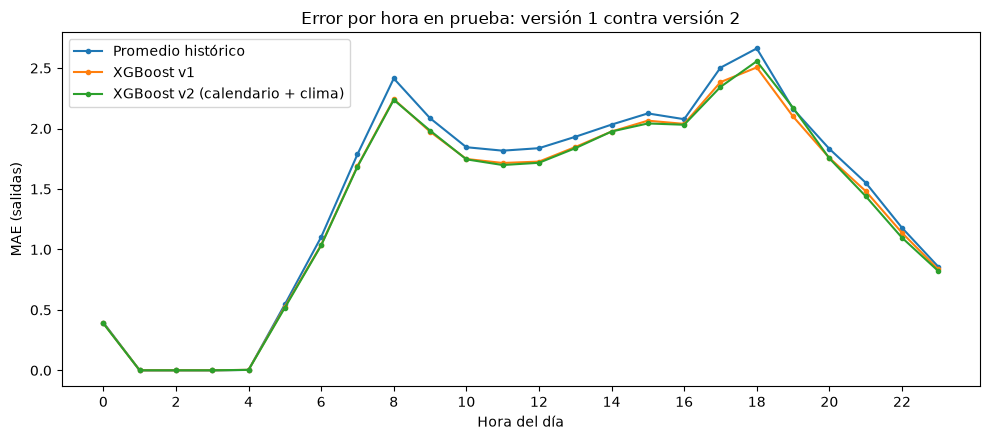

In [9]:
# Error por hora del día (MAE): v1 contra v2
fig, ax = plt.subplots(figsize=(10, 4.5))
for nombre in ["Promedio histórico", "XGBoost v1", "XGBoost v2 (calendario + clima)"]:
    e = M.error_por(test, preds[nombre], "hora")
    ax.plot(e.index, e["MAE"], marker="o", ms=3, label=nombre)
ax.set_xlabel("Hora del día")
ax.set_ylabel("MAE (salidas)")
ax.set_title("Error por hora en prueba: versión 1 contra versión 2")
ax.set_xticks(range(0, 24, 2))
ax.legend()
fig.tight_layout()
fig.savefig("../figures/12_error_por_hora_v2.png", dpi=150)
plt.show()

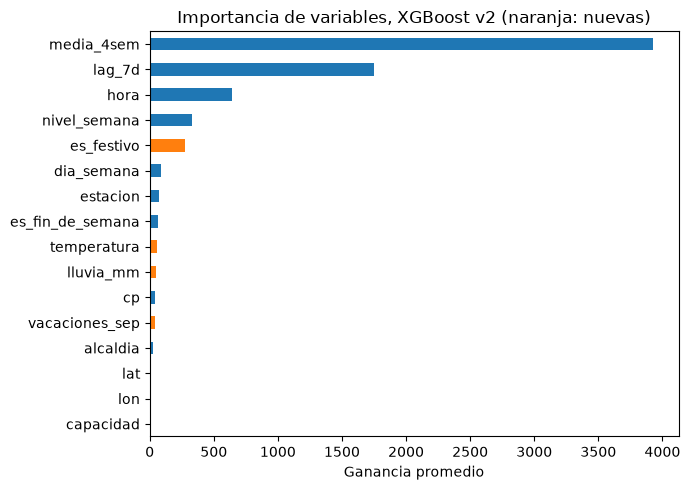

In [10]:
# Importancia de variables de la versión 2 (ganancia promedio)
imp = pd.Series(modelos["XGBoost v2 (calendario + clima)"].get_booster().get_score(importance_type="gain")).sort_values()
fig, ax = plt.subplots(figsize=(7, 5))
imp.plot.barh(ax=ax, color=["C1" if c in M.FEATURES_CALENDARIO + M.FEATURES_CLIMA else "C0" for c in imp.index])
ax.set_xlabel("Ganancia promedio")
ax.set_title("Importancia de variables, XGBoost v2 (naranja: nuevas)")
fig.tight_layout()
fig.savefig("../figures/13_importancia_variables_v2.png", dpi=150)
plt.show()